# Simon's Algorithm

A function f maps n bits to n bits and hides a **secret string s**:
f(x) = f(y) exactly when y = x or y = x ⊕ s.
If s = 00…0, f is one-to-one; otherwise f is two-to-one.
Classically, finding s needs about 2<sup>n/2</sup> calls to f (looking for a collision);
Simon's algorithm needs only about **n** quantum calls, an exponential speed-up.

Circuit (2n qubits: q[0]..q[n−1] input x, q[n]..q[2n−1] output):
1. H on the input qubits → superposition of all x.
2. **Oracle** |x⟩|0⟩ → |x⟩|f(x)⟩: copy x to the output with CNOTs, then, if s ≠ 0, use one qubit j
   where s has a 1 to apply CNOTs onto the output qubits where s has a 1 (so f(x) = f(x ⊕ s)).
3. H on the input qubits again and measure them.

Every measured string y satisfies **y·s = 0 (mod 2)**. Classical post-processing then finds the only
non-zero s that is orthogonal to all measured y (if none exists, s = 00…0).

**Input:** the secret string s (e.g. `110`). n is its length.
**Expected:** every measured y has y·s = 0, and the recovered s equals the input (`Correct: True`).
The second cell saves the circuit diagram as a PNG.

Enter the secret bit string s (e.g. 110): 110


Number of input qubits n = 3 (total qubits = 6)

Counts: {'000': 245, '110': 249, '111': 274, '001': 256}

Equations from the measured strings:
  y = 000:  y.s = 0 (mod 2)
  y = 001:  y.s = 0 (mod 2)
  y = 110:  y.s = 0 (mod 2)
  y = 111:  y.s = 0 (mod 2)

Secret string s: 110
Recovered s    : 110
Function f is  : two-to-one
Correct: True


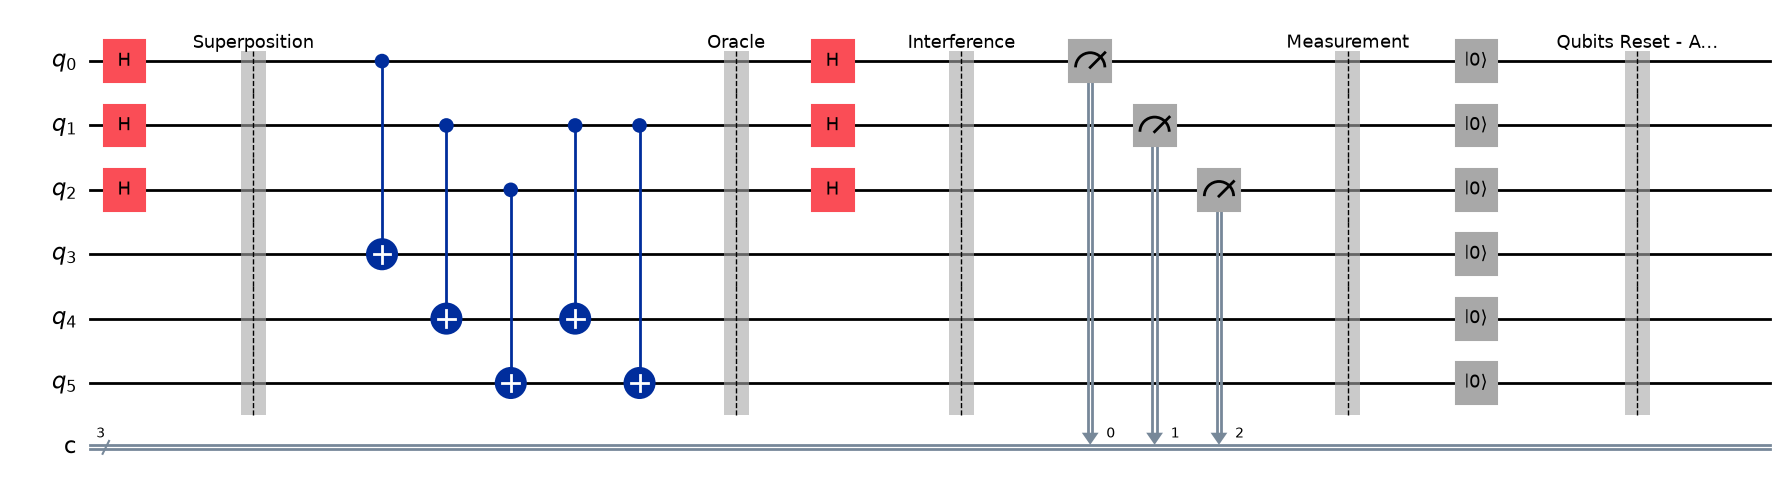

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator

# Input secret string
s = input("Enter the secret bit string s (e.g. 110): ").strip()

if s == "" or set(s) - {"0", "1"}:
    raise ValueError("Enter a string of 0s and 1s.")

n = len(s)
print(f"Number of input qubits n = {n} (total qubits = {2 * n})")

# Registers: q[0]..q[n-1] = input x, q[n]..q[2n-1] = output f(x)
q = QuantumRegister(2 * n, 'q')
c = ClassicalRegister(n, 'c')

qc = QuantumCircuit(q, c)

# Superposition on the input register
for i in range(n):
    qc.h(q[i])
qc.barrier(label="Superposition")

# Oracle: |x>|0> -> |x>|f(x)> with f(x) = f(x XOR s)
# s is written q[n-1]...q[0], like Qiskit results
for i in range(n):
    qc.cx(q[i], q[n + i])              # copy x to the output

if "1" in s:
    j = s[::-1].index("1")             # a qubit where s has a 1
    for i in range(n):
        if s[n - 1 - i] == "1":
            qc.cx(q[j], q[n + i])
qc.barrier(label="Oracle")

# Interference
for i in range(n):
    qc.h(q[i])
qc.barrier(label="Interference")

# Measurement of the input register
for i in range(n):
    qc.measure(q[i], c[i])
qc.barrier(label="Measurement")

# Reset all qubits after measurement
for i in range(2 * n):
    qc.reset(q[i])
qc.barrier(label="Qubits Reset - Available for Reuse")

# Run circuit
result = AerSimulator().run(qc, shots=1024).result()
counts = result.get_counts()
print("\nCounts:", counts)


# Dot product of two bit strings (mod 2)
def dot(a, b):
    return sum(int(x) * int(y) for x, y in zip(a, b)) % 2


# Every measured y satisfies y.s = 0
print("\nEquations from the measured strings:")
for y in sorted(counts):
    print(f"  y = {y}:  y.s = {dot(y, s)} (mod 2)")

# Classical post-processing: non-zero strings orthogonal to every measured y
candidates = []
for k in range(1, 2 ** n):
    guess = format(k, f"0{n}b")
    if all(dot(y, guess) == 0 for y in counts):
        candidates.append(guess)

found = candidates[0] if len(candidates) == 1 else "0" * n

print("\nSecret string s:", s)
print("Recovered s    :", found)
print("Function f is  :", "one-to-one" if found == "0" * n else "two-to-one")
print("Correct:", found == s)

# Draw circuit
qc.draw(output='mpl', fold=-1, scale=1.0)

In [2]:
fig = qc.draw(output="mpl", fold=-1, scale=1.0)
fig.savefig("7_Simon.png", dpi=300, bbox_inches="tight")